# Master H1 Figure — Carpet + Split-Half (merged)

Merges `10_PlotIndivdiual` (per-receiver **carpet**) with `03_H1_Plot_Figure2` (**split-half** lines + **stats**).

**Left column, per channel:** the individual receivers (carpet) collapse into the two split-half mean lines beneath them (white dashed line marks the two halves). **Right column:** the statistics panel, unchanged.

Set `SPLIT_FROM_CARPET = True` to derive the two lines from the displayed carpet (top half vs bottom half — the literal 'collapse'), or `False` to use your precomputed `*_split_timecourse.csv` so the lines match the stats exactly.

### Imports

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
import warnings
warnings.simplefilter('ignore')

# project helpers (from notebook 10); msuthemes optional (from notebook 03)
try:
    import utils.process_analysis
except ImportError as e:
    print(f'utils.process_analysis import failed: {e}')
try:
    from msuthemes import theme_msu, colors
except ImportError:
    pass

### Configuration of paths and variables

In [2]:
# raw per-subject combined data -> carpet (from notebook 10)
DATA_DIR        = '../data/02_processed_combined_data'
CONDITIONS_FILE = os.path.abspath(os.path.join(os.getcwd(), '../data/sub_conditions.csv'))

# precomputed H1 results -> stats + (optional) split timecourses (from notebook 03)
RESULTS_DIR = '../data/04_analysis/h1_results/no_prior_exposure'
OUTPUT_PLOT = os.path.join(RESULTS_DIR, 'Master_H1_Carpet_SplitHalf.png')

signals = ['Gaze_X', 'Gaze_Y', 'Pupil_Mean', 'Heart_Rate', 'GSR']
signal_titles = {'Gaze_X': 'Gaze X', 'Gaze_Y': 'Gaze Y', 'Pupil_Mean': 'Pupil Dilation',
                 'Heart_Rate': 'Heart Rate', 'GSR': 'GSR'}

VMIN, VMAX       = -2.0, 2.0
MAX_TIME_SEC     = 319
SPLIT_FROM_CARPET = True   # True: collapse the displayed carpet; False: use precomputed CSVs

### Load individual subject matrices (carpet)
From notebook 10. `matrices[signal]` is z-scored per receiver, shape `(n_receivers, n_samples)`.

In [3]:
pc_subjs = utils.process_analysis.get_subjects_by_condition(
    CONDITIONS_FILE, target_condition='PC', exclude_prior_exposure=False)
results = utils.process_analysis.load_filtered_physiological_data(DATA_DIR, pc_subjs)

# zscore each column (receiver) across time, then transpose -> (n_receivers, n_samples)
matrices = {s: zscore(results[s], axis=0).T for s in signals}
for s in signals:
    print(f'{s:12s} carpet shape (receivers x samples): {matrices[s].shape}')

Scanning 193 files against 99 subject IDs...
Successfully loaded 96 valid subjects.
Gaze_X       carpet shape (receivers x samples): (96, 6381)
Gaze_Y       carpet shape (receivers x samples): (96, 6381)
Pupil_Mean   carpet shape (receivers x samples): (96, 6381)
Heart_Rate   carpet shape (receivers x samples): (96, 6381)
GSR          carpet shape (receivers x samples): (96, 6381)


### Load precomputed stats + null distributions
From notebook 03. Split timecourses are only needed when `SPLIT_FROM_CARPET = False`.

In [4]:
stats_df = pd.read_csv(os.path.join(RESULTS_DIR, 'h1_summary_stats.csv')).set_index('Signal')
null_dists = {s: np.load(os.path.join(RESULTS_DIR, f'{s}_null_dist.npy')) for s in signals}

split_timecourses = None
if not SPLIT_FROM_CARPET:
    split_timecourses = {s: pd.read_csv(os.path.join(RESULTS_DIR, f'{s}_split_timecourse.csv'))
                         for s in signals}

### Figure function
Outer 5×2 grid (`width_ratios=[4, 1]`). Each left cell is split into a tall carpet row over a short split-half row sharing the time axis; the right cell is the stats panel. (Note: this fixes the `real_matrix` reference from notebook 10 by using each matrix's own row count for the carpet extent.)

In [5]:
def make_master_figure(matrices, stats_df, null_dists, signals, signal_titles,
                       max_time_sec=319, vmin=-2.0, vmax=2.0, cmap="RdBu_r",
                       split_from_carpet=True, split_timecourses=None,
                       outpath=None):
    """
    Per channel (row):
      LEFT  = carpet of individual receivers (top) collapsing into the
              split-half mean lines (bottom), sharing the time axis.
      RIGHT = null-distribution histogram + observed pairwise/split-half ISC.

    matrices         : {signal -> (n_receivers, n_samples)} z-scored per receiver
    stats_df         : indexed by signal; cols Split_Half_r, Observed_ISC, Phase_Rand_P
    null_dists       : {signal -> 1d array}
    split_from_carpet: True  -> split lines = top half vs bottom half of the carpet
                       False -> read Group_1/Group_2 from split_timecourses[signal]
    """
    sns.set_theme(font="Arial")
    sns.set(style="ticks", context="paper")

    fig = plt.figure(figsize=(13, 14))
    outer = GridSpec(len(signals), 2, figure=fig, width_ratios=[4, 1],
                     hspace=0.5, wspace=0.16)

    carpet_axes = []
    for i, signal in enumerate(signals):
        mat = matrices[signal]                       # (n_recv, n_samples)
        n_recv, n_samp = mat.shape
        t = np.linspace(0, max_time_sec, n_samp)

        # ---- left cell: carpet (top) + split-half (bottom) ----------------
        inner = GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[i, 0],
                                        height_ratios=[2.3, 1.0], hspace=0.08)
        ax_carpet = fig.add_subplot(inner[0])
        ax_split = fig.add_subplot(inner[1], sharex=ax_carpet)
        ax_stats = fig.add_subplot(outer[i, 1])
        carpet_axes.append(ax_carpet)

        # carpet
        im = ax_carpet.imshow(mat, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax,
                              extent=[0, max_time_sec, n_recv, 0],
                              interpolation="none")
        ax_carpet.set_title(signal_titles[signal], fontsize=16, pad=8)
        ax_carpet.set_ylabel("Receivers", fontsize=11)
        ax_carpet.set_yticks([])
        plt.setp(ax_carpet.get_xticklabels(), visible=False)
        ax_carpet.tick_params(bottom=False)
        # dashed line marking the two halves that get averaged
        ax_carpet.axhline(n_recv / 2, color="white", lw=1.0, ls="--", alpha=0.9)

        # split-half collapse
        if split_from_carpet:
            g1 = mat[: n_recv // 2].mean(0)
            g2 = mat[n_recv // 2:].mean(0)
            g1 = (g1 - g1.mean()) / g1.std()
            g2 = (g2 - g2.mean()) / g2.std()
            x = t
        else:
            tc = split_timecourses[signal]
            x = tc["Time_Sec"].values
            g1, g2 = tc["Group_1"].values, tc["Group_2"].values

        ax_split.plot(x, g1, color="darkred", lw=2, alpha=0.85, label="Split 1")
        ax_split.plot(x, g2, color="darkblue", lw=2, alpha=0.7, label="Split 2")
        ax_split.set_ylabel("Signal", fontsize=11)
        ax_split.set_yticks([])
        ax_split.set_ylim([-3.2, 3.2])
        ax_split.set_xlim(0, max_time_sec)
        if i == len(signals) - 1:
            ax_split.set_xlabel("Time (seconds)", fontsize=13)
        else:
            plt.setp(ax_split.get_xticklabels(), visible=False)
            ax_split.tick_params(bottom=False)

        # ---- right cell: statistics (kept as in notebook 03) --------------
        r_split = stats_df.loc[signal, "Split_Half_r"]
        obs_isc = stats_df.loc[signal, "Observed_ISC"]
        sns.histplot(null_dists[signal], kde=True, color="lightslategrey",
                     alpha=0.5, ax=ax_stats, label="Null Distr.")
        ax_stats.axvline(obs_isc, color="darkgreen", linestyle="-.", linewidth=3,
                         label="Obs. ISC (pairw.)")
        ax_stats.axvline(r_split, color="darkgreen", linestyle="-", linewidth=3,
                         label="Obs. ISC (split-h.)")
        ax_stats.set_xlim([0, 1])
        ax_stats.set_title("Statistics", fontsize=16, loc="center")
        ax_stats.set_ylabel("")
        ax_stats.set_yticks([])
        ax_stats.tick_params(axis="x", labelsize=9)
        ax_stats.set_xlabel("Pearson r", fontsize=13) if i == len(signals) - 1 \
            else ax_stats.set_xlabel("")

        # row-0 labels (as in notebook 03, but in axes-fraction coords so they
        # don't drift if the histogram bin counts change)
        if i == 0:
            ax_stats.text(0.03, 0.95, "Null\nDistr.\n(pairw.)", va="top",
                          transform=ax_stats.transAxes, fontsize=11,
                          color="lightslategrey")
            ax_stats.text(0.40, 0.62, "Obs.\nISC\n(pairw.)", va="top",
                          transform=ax_stats.transAxes, fontsize=11,
                          color="darkgreen")
            ax_stats.text(0.74, 0.32, "Obs.\nISC\n(split-h.)", va="top",
                          transform=ax_stats.transAxes, fontsize=11,
                          color="darkgreen")

    # legend on the top-row split-half axes
    # axes are added per row as (carpet, split, stats), so row-0 split is index 1
    fig.axes[1].legend(loc="upper right", fontsize=9, frameon=True,
                       framealpha=0.8, ncol=2)

    sns.despine()

    # shared colorbar in the gap, aligned to the middle carpet
    fig.canvas.draw()
    pos = carpet_axes[len(signals) // 2].get_position()
    cax = fig.add_axes([pos.x1 + 0.012, pos.y0, 0.011, pos.height])
    fig.colorbar(im, cax=cax, label="Z-score")

    if outpath:
        fig.savefig(outpath, dpi=300, bbox_inches="tight")
    return fig

### Build the figure

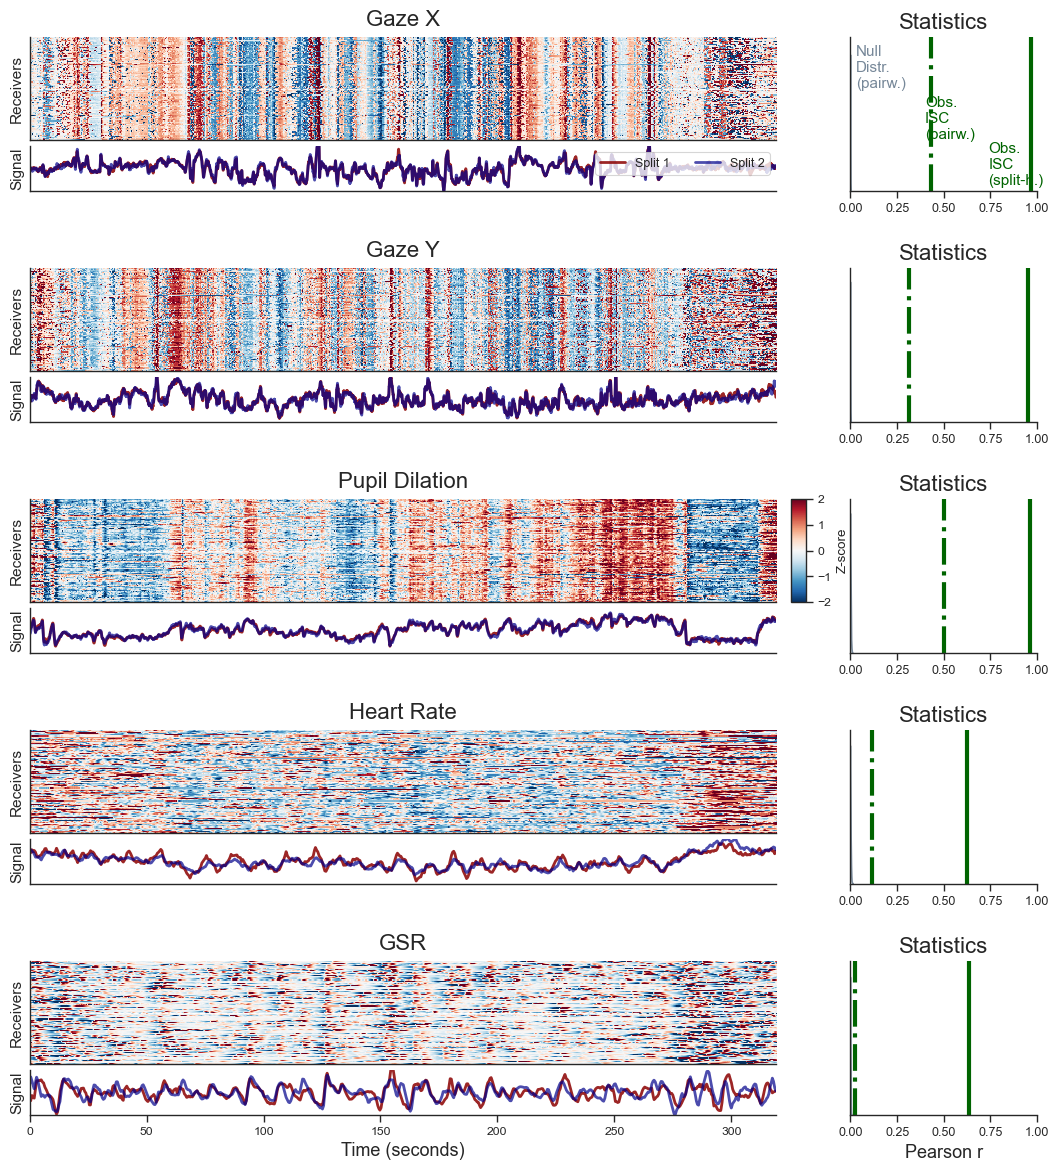

Saved to ../data/04_analysis/h1_results/no_prior_exposure/Master_H1_Carpet_SplitHalf.png


In [6]:
fig = make_master_figure(
    matrices, stats_df, null_dists, signals, signal_titles,
    max_time_sec=MAX_TIME_SEC, vmin=VMIN, vmax=VMAX,
    split_from_carpet=SPLIT_FROM_CARPET, split_timecourses=split_timecourses,
    outpath=OUTPUT_PLOT,
)
plt.show()
print(f'Saved to {OUTPUT_PLOT}')